# 07a — CNN Breakout: MaxPool, Backpropagation, and a Full Forward Pass

This is a **follow-up / breakout notebook** for Notebook 07, designed to pause around the feature-map section and make three pieces much less magical:

1. **MaxPool1d:** what it literally keeps, what it throws away, and what it looks like on our learned feature maps.
2. **PyTorch + backpropagation:** what `.to(device)`, `.detach()`, `.cpu()`, `.numpy()`, `zero_grad()`, `backward()`, and `step()` are actually doing.
3. **The whole model:** carry a real IMU window through **every stage** from the raw 6 × 100 waveform to logits, softmax probabilities, and the final prediction.

The notebook repeats a small amount of setup so it can run by itself.

> **Optional shortcut from Notebook 07:** after training the demonstration model there, run
>
> ```python
> torch.save(model.state_dict(), "imu_cnn_demo_state.pt")
> ```
>
> This notebook will load that exact model if the file is present. Otherwise it trains a fresh demonstration model, which is tiny and fast.


## 0. Setup

We use the same blinded development data, the same first held-out subject, and the same CNN architecture as Notebook 07.

One reminder before the code:

```text
NumPy windows:   [window, time, channel] = [N, 100, 6]
PyTorch Conv1d:  [batch, channel, time]  = [N, 6, 100]
```


In [1]:
%matplotlib inline

from pathlib import Path
from collections import Counter
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch:", torch.__version__)

# Choose the fastest accelerator PyTorch can actually use.
# `device` is a torch.device object such as device(type='mps') or device(type='cpu').
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)


PyTorch: 2.14.1
Device: mps


In [2]:
# Look for the same blinded class dataset in a few likely locations.
DATA_CANDIDATES = [
    Path("train_blinded_20261015.npz"),
    Path("train_blinded.npz"),
    Path("imu_harmonized_20261015/train_blinded_20261015.npz"),
    Path("STUDENT_SHARE_BUNDLE_20261015/train_blinded_20261015.npz"),
]

DATA_PATH = next(
    (p for p in DATA_CANDIDATES if p.exists()),
    None,
)

assert DATA_PATH is not None, (
    "Could not find train_blinded_20261015.npz. "
    "Put the NPZ beside this notebook or in imu_harmonized_20261015/."
)

# np.load returns NumPy arrays from the compressed .npz archive.
data = np.load(DATA_PATH, allow_pickle=False)

# Raw windows arrive as [window, time, channel].
X_windows = data["X_windows"].astype(np.float32)
y_windows = data["y_windows"].astype(str)
subject_ids = data["subject_id"].astype(str)
CHANNELS = data["channel_names"].astype(str).tolist()
FS = float(data["sample_rate_hz"])

# np.unique sorts the activity names and gives us a stable list of classes.
class_names = np.unique(y_windows)
class_to_index = {name: i for i, name in enumerate(class_names)}

# CrossEntropyLoss wants integer class IDs, not strings.
y_int = np.array(
    [class_to_index[name] for name in y_windows],
    dtype=np.int64,
)

# torch.from_numpy creates a PyTorch tensor from the NumPy data.
# permute changes dimension order from [N, time, channel] to [N, channel, time].
# contiguous makes the rearranged tensor occupy a conventional contiguous memory layout.
X_tensor = torch.from_numpy(X_windows).permute(0, 2, 1).contiguous()
y_tensor = torch.from_numpy(y_int)

print("Data:", DATA_PATH)
print("X_windows:", X_windows.shape)
print("X_tensor:", tuple(X_tensor.shape))
print("Classes:", class_names)
print("Subjects:", np.unique(subject_ids))
print("Sampling rate:", FS, "Hz")


Data: STUDENT_SHARE_BUNDLE_20261015/train_blinded_20261015.npz
X_windows: (2179, 100, 6)
X_tensor: (2179, 6, 100)
Classes: ['StairsDown' 'Standing' 'Walking']
Subjects: ['subject01' 'subject05' 'subject06' 'subject07' 'subject08' 'subject09'
 'subject10']
Sampling rate: 50.0 Hz


## 1. Re-create the same CNN

The architecture is unchanged from Notebook 07:

```text
6 × 100 raw IMU
    ↓ standardize
Conv1d 6→32, kernel 9 + ReLU
    ↓
MaxPool1d(2)
    ↓
Conv1d 32→64, kernel 7 + ReLU
    ↓
MaxPool1d(2)
    ↓
Conv1d 64→64, kernel 5 + ReLU
    ↓
AdaptiveAvgPool1d(1)
    ↓
Linear 64→32 + ReLU
    ↓
Linear 32→3
    ↓
logits
```

Notice that `forward_features()` in Notebook 07 skipped returning the pooling outputs. Here we will expose **everything**.


In [3]:
class IMUCNN(nn.Module):
    def __init__(self, channel_mean, channel_std, n_classes):
        super().__init__()

        # Buffers are persistent model state that move with .to(device),
        # but they are NOT trainable parameters and receive no gradients.
        self.register_buffer("channel_mean", channel_mean.clone())
        self.register_buffer(
            "channel_std",
            channel_std.clone().clamp_min(1e-6),
        )

        self.conv1 = nn.Conv1d(6, 32, kernel_size=9, padding=4)
        self.pool1 = nn.MaxPool1d(2)

        self.conv2 = nn.Conv1d(32, 64, kernel_size=7, padding=3)
        self.pool2 = nn.MaxPool1d(2)

        self.conv3 = nn.Conv1d(64, 64, kernel_size=5, padding=2)
        self.gap = nn.AdaptiveAvgPool1d(1)

        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, n_classes)

    def standardize(self, x):
        return (x - self.channel_mean) / self.channel_std

    def forward(self, x):
        x = self.standardize(x)
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        x = F.relu(self.conv3(x))
        x = self.gap(x).squeeze(-1)
        x = F.relu(self.fc1(x))
        logits = self.fc2(x)
        return logits


def training_channel_stats(X_train_tensor):
    # Average across all TRAINING windows and all time samples.
    # Keep one value per sensor channel.
    mean = X_train_tensor.mean(dim=(0, 2), keepdim=True)
    std = X_train_tensor.std(dim=(0, 2), keepdim=True)
    return mean, std


def build_model(X_train_tensor, n_classes):
    mean, std = training_channel_stats(X_train_tensor)
    model = IMUCNN(mean, std, n_classes)
    return model.to(device)


In [4]:
# Same demonstration split used in Notebook 07:
# hold out ONE WHOLE PERSON.
DEMO_VAL_SUBJECT = np.unique(subject_ids)[0]

train_mask = subject_ids != DEMO_VAL_SUBJECT
val_mask = subject_ids == DEMO_VAL_SUBJECT

X_train = X_tensor[train_mask]
y_train = y_tensor[train_mask]
X_val = X_tensor[val_mask]
y_val = y_tensor[val_mask]

print("Validation subject:", DEMO_VAL_SUBJECT)
print("Training:", tuple(X_train.shape), Counter(y_windows[train_mask]))
print("Validation:", tuple(X_val.shape), Counter(y_windows[val_mask]))


Validation subject: subject01
Training: (1948, 6, 100) Counter({np.str_('Walking'): 829, np.str_('StairsDown'): 603, np.str_('Standing'): 516})
Validation: (231, 6, 100) Counter({np.str_('Walking'): 144, np.str_('Standing'): 54, np.str_('StairsDown'): 33})


### Load the Notebook 07 model if possible; otherwise train a fresh one

This setup cell is intentionally compact. Later we will explode the training loop into individual PyTorch operations and comment it almost to death. 😄


In [5]:
def make_loader(X, y, batch_size=128, shuffle=False):
    return DataLoader(
        TensorDataset(X, y),
        batch_size=batch_size,
        shuffle=shuffle,
    )


def class_weights_from_labels(y_train, n_classes):
    counts = torch.bincount(y_train, minlength=n_classes).float()
    return len(y_train) / (n_classes * counts)


def quick_train(model, max_epochs=40, patience=5):
    train_loader = make_loader(X_train, y_train, batch_size=128, shuffle=True)
    val_loader = make_loader(X_val, y_val, batch_size=256, shuffle=False)

    weights = class_weights_from_labels(y_train, len(class_names)).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_loss = np.inf
    best_state = None
    stale = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss_sum = 0.0
        n = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                logits = model(X_batch)
                loss = loss_fn(logits, y_batch)
                val_loss_sum += loss.item() * len(y_batch)
                n += len(y_batch)

        val_loss = val_loss_sum / n
        print(f"epoch {epoch:02d} | val loss {val_loss:.3f}")

        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                print("early stopping")
                break

    model.load_state_dict(best_state)
    return model


torch.manual_seed(42)
model = build_model(X_train, len(class_names))

CHECKPOINT_PATH = Path("imu_cnn_demo_state.pt")

if CHECKPOINT_PATH.exists():
    print("Loading model from", CHECKPOINT_PATH)
    state = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(state)
else:
    print("No saved Notebook 07 checkpoint found; training a fresh demo model.")
    t0 = time.time()
    model = quick_train(model)
    print(f"Training time: {time.time() - t0:.1f} s")
    torch.save(model.state_dict(), CHECKPOINT_PATH)
    print("Saved", CHECKPOINT_PATH)

model.eval()
print("Model device:", next(model.parameters()).device)


Loading model from imu_cnn_demo_state.pt
Model device: mps:0


# Part I — MaxPool1d: what is it actually doing?

A convolution filter answers:

> **How strongly does this learned pattern match here?**

After ReLU, those match scores are nonnegative. `MaxPool1d(2)` then looks at neighboring pairs and keeps only the larger activation.

With the default stride, `MaxPool1d(2)` does:

```text
[a0, a1, a2, a3, a4, a5, ...]
  \ /      \ /      \ /
 max       max       max
   ↓         ↓         ↓
[p0,       p1,       p2, ...]
```

So the time dimension is cut in half.


## 2. MaxPool on a toy feature map

First, no CNN at all. Just pretend these eight numbers are the ReLU output of **one filter** at eight neighboring time locations.


In [6]:
# One batch, one feature-map channel, eight time positions.
toy = torch.tensor([
    0.10, 0.70,
    0.30, 0.20,
    1.10, 0.40,
    0.15, 0.90,
], dtype=torch.float32).reshape(1, 1, 8)

pool = nn.MaxPool1d(kernel_size=2)
pooled = pool(toy)

print("Before pooling:", toy.flatten().tolist())
print("After pooling: ", pooled.flatten().tolist())
print("Shape before:", tuple(toy.shape))
print("Shape after: ", tuple(pooled.shape))


Before pooling: [0.10000000149011612, 0.699999988079071, 0.30000001192092896, 0.20000000298023224, 1.100000023841858, 0.4000000059604645, 0.15000000596046448, 0.8999999761581421]
After pooling:  [0.699999988079071, 0.30000001192092896, 1.100000023841858, 0.8999999761581421]
Shape before: (1, 1, 8)
Shape after:  (1, 1, 4)


In [7]:
# Make the exact pooling operation visible as a table.
rows = []

values = toy.flatten().numpy()
pooled_values = pooled.flatten().numpy()

for i in range(len(pooled_values)):
    left = values[2 * i]
    right = values[2 * i + 1]

    rows.append({
        "pool output": i,
        "input index 1": 2 * i,
        "value 1": left,
        "input index 2": 2 * i + 1,
        "value 2": right,
        "max kept": pooled_values[i],
    })

pool_table = pd.DataFrame(rows)
display(pool_table)


,pool output,input index 1,value 1,input index 2,value 2,max kept
0,0,0,0.10,1,0.7,0.7
1,1,2,0.30,3,0.2,0.3
2,2,4,1.10,5,0.4,1.1
3,3,6,0.15,7,0.9,0.9


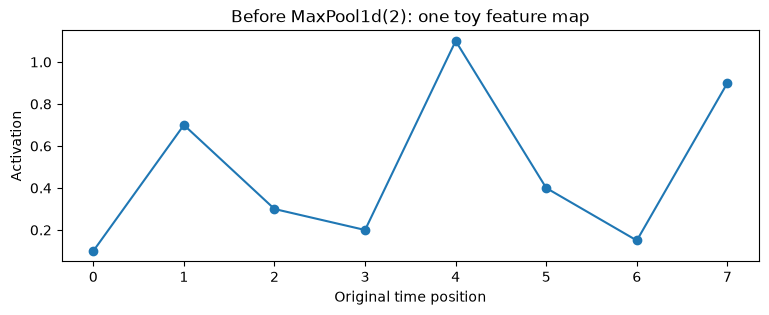

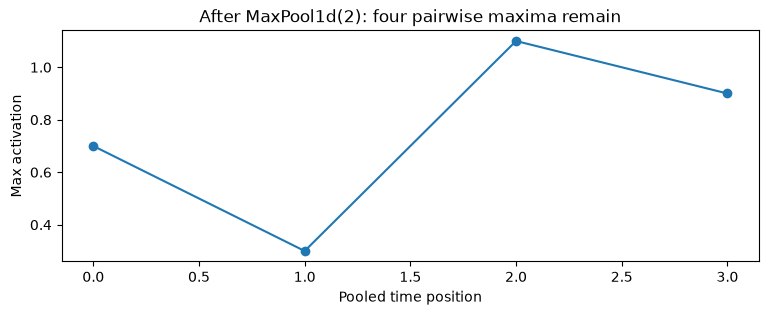

In [8]:
# Plot the original feature-map activations.
plt.figure(figsize=(9, 3))
plt.plot(np.arange(8), values, marker="o")
plt.xlabel("Original time position")
plt.ylabel("Activation")
plt.title("Before MaxPool1d(2): one toy feature map")
plt.show()

# Plot the pooled feature map.
plt.figure(figsize=(9, 3))
plt.plot(np.arange(4), pooled_values, marker="o")
plt.xlabel("Pooled time position")
plt.ylabel("Max activation")
plt.title("After MaxPool1d(2): four pairwise maxima remain")
plt.show()


### What MaxPool throws away

Pooling is intentionally lossy. For example:

```text
[0.2, 0.9] → 0.9
[0.9, 0.2] → 0.9
```

After pooling, we no longer know **which member of the pair** contained the peak.

And:

```text
[0.9, 0.8] → 0.9
[0.9, 0.1] → 0.9
```

We also lose the smaller value entirely.

That loss of detail is partly the point: the later network becomes less sensitive to tiny changes in **exact timing**.


## 3. MaxPool on a real learned Conv1 feature map

Now use a real held-out Walking window and the **trained first convolutional layer**.

We will explicitly compute:

```text
raw input
→ standardize
→ Conv1
→ ReLU
→ MaxPool1
```


In [9]:
walking_class = class_to_index["Walking"]
walking_candidates = np.where(y_val.numpy() == walking_class)[0]
example_index = walking_candidates[len(walking_candidates) // 2]

# Slice with [idx:idx+1] instead of [idx] so we KEEP a batch dimension of size 1.
example = X_val[example_index:example_index + 1].to(device)

model.eval()

with torch.no_grad():
    # Same operations as the model's forward pass, but exposed one at a time.
    x_std = model.standardize(example)
    conv1_scores = model.conv1(x_std)
    a1 = F.relu(conv1_scores)
    p1 = model.pool1(a1)

print("raw input:   ", tuple(example.shape))
print("standardized:", tuple(x_std.shape))
print("Conv1 scores:", tuple(conv1_scores.shape))
print("Conv1 + ReLU:", tuple(a1.shape))
print("Pool1:       ", tuple(p1.shape))


raw input:    (1, 6, 100)
standardized: (1, 6, 100)
Conv1 scores: (1, 32, 100)
Conv1 + ReLU: (1, 32, 100)
Pool1:        (1, 32, 50)


Filter: 19


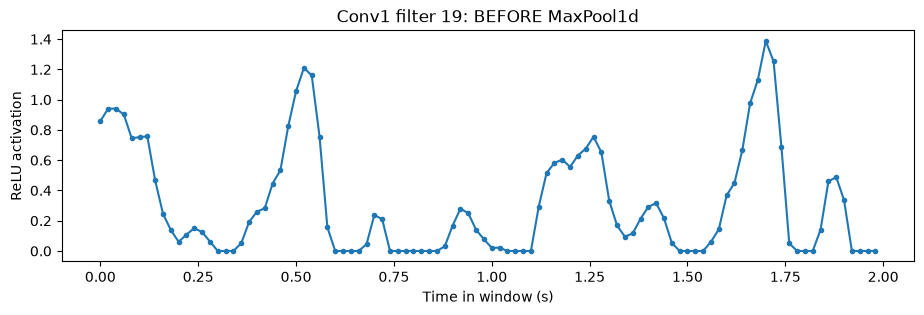

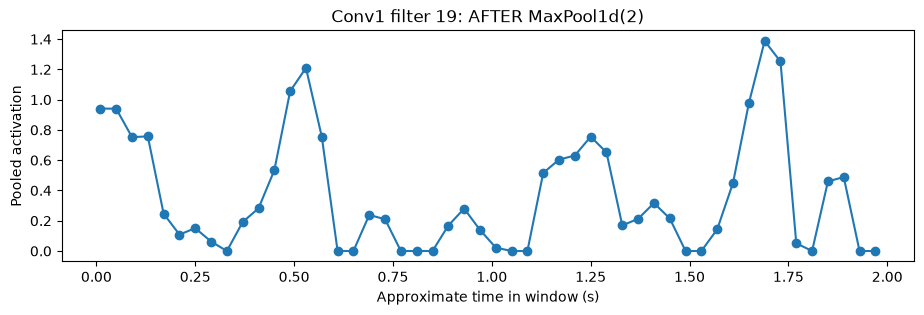

In [10]:
# Pick the Conv1 filter that is most active ON AVERAGE for this window.
# This is just a convenient filter to inspect, not a claim that it is the most biologically important.
best_filter1 = int(a1[0].mean(dim=1).argmax().item())

before = a1[0, best_filter1].detach().cpu().numpy()
after = p1[0, best_filter1].detach().cpu().numpy()

# Time coordinates: Conv1 has 100 positions at 50 Hz.
t_before = np.arange(len(before)) / FS

# Pool1 has 50 positions. Each output summarizes two neighboring original positions.
t_after = (2 * np.arange(len(after)) + 0.5) / FS

print("Filter:", best_filter1)

plt.figure(figsize=(11, 3))
plt.plot(t_before, before, marker=".")
plt.xlabel("Time in window (s)")
plt.ylabel("ReLU activation")
plt.title(f"Conv1 filter {best_filter1}: BEFORE MaxPool1d")
plt.show()

plt.figure(figsize=(11, 3))
plt.plot(t_after, after, marker="o")
plt.xlabel("Approximate time in window (s)")
plt.ylabel("Pooled activation")
plt.title(f"Conv1 filter {best_filter1}: AFTER MaxPool1d(2)")
plt.show()


In [11]:
# Verify numerically that Pool1 is taking pairwise maxima.
rows = []

for i in range(min(12, len(after))):
    left = before[2 * i]
    right = before[2 * i + 1]

    rows.append({
        "pooled index": i,
        "activation[2i]": left,
        "activation[2i+1]": right,
        "manual max": max(left, right),
        "PyTorch pool output": after[i],
    })

pool1_check = pd.DataFrame(rows)
display(pool1_check)

print(
    "All pairwise maxima match PyTorch:",
    np.allclose(
        np.maximum(before[0::2], before[1::2]),
        after,
    ),
)


,pooled index,activation[2i],activation[2i+1],manual max,PyTorch pool output
0,0,0.858125,0.941242,0.941242,0.941242
1,1,0.940268,0.901936,0.940268,0.940268
2,2,0.744684,0.752390,0.752390,0.752390
3,3,0.757321,0.466119,0.757321,0.757321
4,4,0.246435,0.138325,0.246435,0.246435
5,5,0.060554,0.108634,0.108634,0.108634
6,6,0.150765,0.124993,0.150765,0.150765
7,7,0.062463,0.000000,0.062463,0.062463
8,8,0.000000,0.000000,0.000000,0.000000
9,9,0.051753,0.191679,0.191679,0.191679


All pairwise maxima match PyTorch: True


## 4. The whole feature-map bank before and after Pool1

Each row is one learned filter. Pooling does **not** reduce the number of filters. It reduces only the time resolution:

```text
32 filters × 100 time positions
              ↓ MaxPool1d(2)
32 filters ×  50 time positions
```


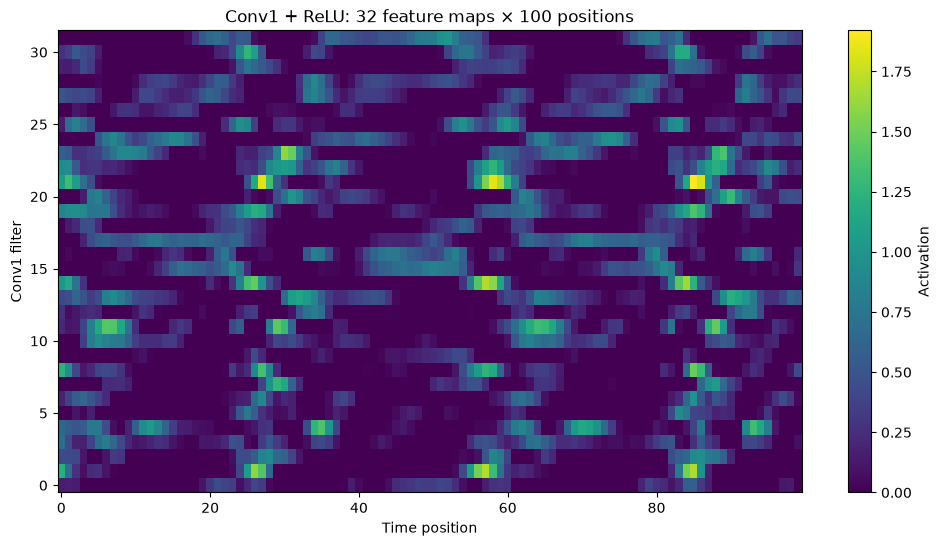

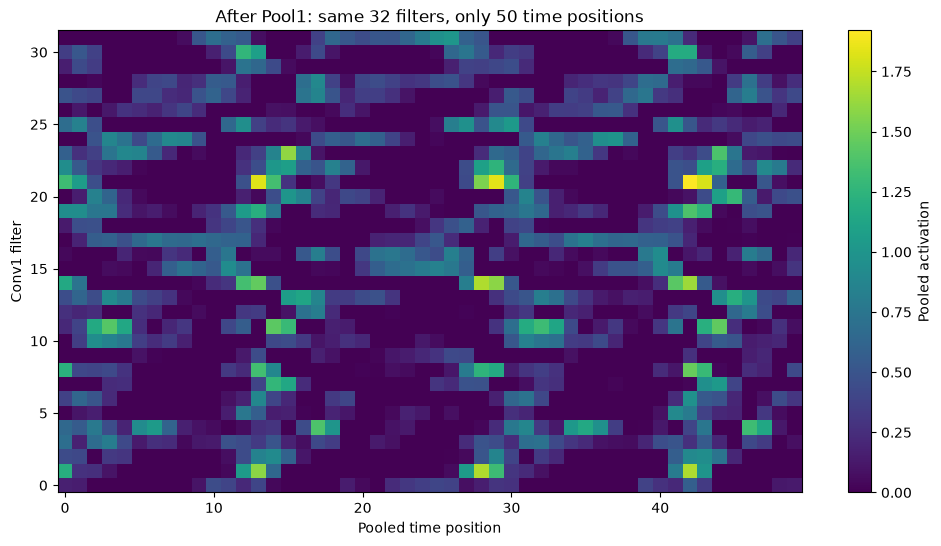

In [12]:
a1_np = a1[0].detach().cpu().numpy()
p1_np = p1[0].detach().cpu().numpy()

plt.figure(figsize=(12, 6))
plt.imshow(a1_np, aspect="auto", origin="lower")
plt.xlabel("Time position")
plt.ylabel("Conv1 filter")
plt.title("Conv1 + ReLU: 32 feature maps × 100 positions")
plt.colorbar(label="Activation")
plt.show()

plt.figure(figsize=(12, 6))
plt.imshow(p1_np, aspect="auto", origin="lower")
plt.xlabel("Pooled time position")
plt.ylabel("Conv1 filter")
plt.title("After Pool1: same 32 filters, only 50 time positions")
plt.colorbar(label="Pooled activation")
plt.show()


## 5. Pool2 does the same idea one level deeper

At this point the 64 Conv2 feature maps already summarize combinations of earlier features. Pool2 again keeps local maxima and halves temporal resolution:

```text
64 × 50 → 64 × 25
```


Conv2 + ReLU: (1, 64, 50)
Pool2:        (1, 64, 25)
Example Conv2 filter: 25


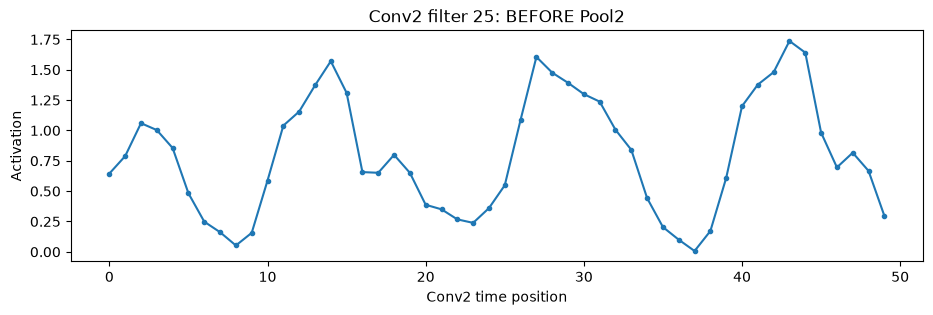

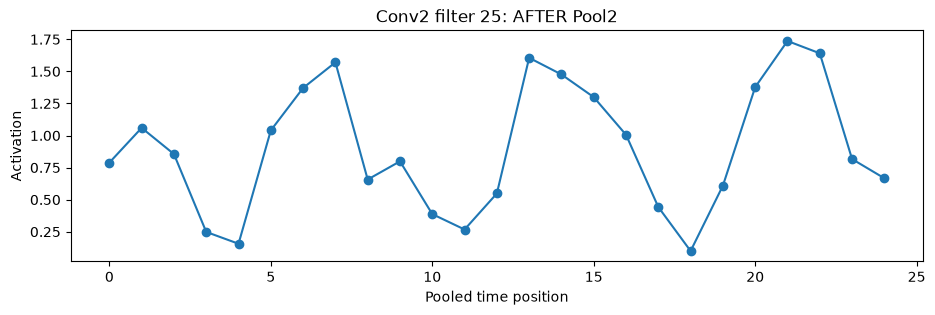

In [13]:
with torch.no_grad():
    conv2_scores = model.conv2(p1)
    a2 = F.relu(conv2_scores)
    p2 = model.pool2(a2)

best_filter2 = int(a2[0].mean(dim=1).argmax().item())

before2 = a2[0, best_filter2].detach().cpu().numpy()
after2 = p2[0, best_filter2].detach().cpu().numpy()

print("Conv2 + ReLU:", tuple(a2.shape))
print("Pool2:       ", tuple(p2.shape))
print("Example Conv2 filter:", best_filter2)

plt.figure(figsize=(11, 3))
plt.plot(np.arange(len(before2)), before2, marker=".")
plt.xlabel("Conv2 time position")
plt.ylabel("Activation")
plt.title(f"Conv2 filter {best_filter2}: BEFORE Pool2")
plt.show()

plt.figure(figsize=(11, 3))
plt.plot(np.arange(len(after2)), after2, marker="o")
plt.xlabel("Pooled time position")
plt.ylabel("Activation")
plt.title(f"Conv2 filter {best_filter2}: AFTER Pool2")
plt.show()


### Pooling checkpoint

Be ready to explain:

1. Why does `MaxPool1d(2)` change `32 × 100` into `32 × 50` rather than `16 × 100`?
2. What exact operation creates one pooled value?
3. What timing information disappears?
4. Why might losing a little exact timing actually help with gait windows that start at arbitrary phases?
5. Why does pooling also make deeper receptive fields grow faster?


# Part II — PyTorch machinery without the incantations

A useful mental map is:

```text
NumPy array
    ↓ torch.from_numpy(...)
CPU tensor
    ↓ .to(device)
CPU / CUDA / MPS tensor
    ↓ model(...)
computation graph + output tensor
    ↓ .detach()
tensor no longer connected to autograd
    ↓ .cpu()
CPU tensor
    ↓ .numpy()
NumPy array for sklearn / pandas / matplotlib
```

The key idea is that **device placement** and **gradient tracking** are two different questions.


## 6. What is actually inside a PyTorch tensor?


In [14]:
# Get one minibatch from the DataLoader.
loader = make_loader(X_train, y_train, batch_size=8, shuffle=False)
X_batch_cpu, y_batch_cpu = next(iter(loader))

print("X type:          ", type(X_batch_cpu))
print("X shape:         ", tuple(X_batch_cpu.shape))
print("X dtype:         ", X_batch_cpu.dtype)
print("X device:        ", X_batch_cpu.device)
print("X requires_grad: ", X_batch_cpu.requires_grad)
print()
print("y shape:         ", tuple(y_batch_cpu.shape))
print("y dtype:         ", y_batch_cpu.dtype)
print("y device:        ", y_batch_cpu.device)


X type:           <class 'torch.Tensor'>
X shape:          (8, 6, 100)
X dtype:          torch.float32
X device:         cpu
X requires_grad:  False

y shape:          (8,)
y dtype:          torch.int64
y device:         cpu


The input data normally have `requires_grad=False` because we are **not trying to optimize the sensor measurements**.

The model weights have `requires_grad=True` because those are the quantities gradient descent should change.


In [15]:
first_parameter = next(model.parameters())

print("First model parameter shape:", tuple(first_parameter.shape))
print("Parameter device:           ", first_parameter.device)
print("Parameter requires_grad:    ", first_parameter.requires_grad)
print()
print("Normalization buffer device:", model.channel_mean.device)
print("Buffer requires_grad:       ", model.channel_mean.requires_grad)


First model parameter shape: (32, 6, 9)
Parameter device:            mps:0
Parameter requires_grad:     True

Normalization buffer device: mps:0
Buffer requires_grad:        False


## 7. `.to(device)`: move data to where the model lives

`.to(device)` does **not** modify the original variable in place. It returns a tensor on the requested device, so we normally assign the result back.


In [16]:
print("Before .to(device):", X_batch_cpu.device)

# Create a device-resident version of the batch.
X_batch = X_batch_cpu.to(device)
y_batch = y_batch_cpu.to(device)

print("After .to(device): ", X_batch.device)
print("Original still on: ", X_batch_cpu.device)
print("Model is on:        ", next(model.parameters()).device)


Before .to(device): cpu
After .to(device):  mps:0
Original still on:  cpu
Model is on:         mps:0


## 8. `.detach()`, `.cpu()`, `.numpy()`: escaping autograd cleanly

Consider a trainable convolution kernel:

```text
model.conv1.weight
```

It is part of the model, lives on the model's device, and requires gradients.

For plotting or sending it to NumPy we often write:

```python
model.conv1.weight.detach().cpu().numpy()
```

Read that from left to right:

- **`.detach()`**: give me a tensor view that is no longer attached to the autograd computation graph.
- **`.cpu()`**: put those values in ordinary CPU memory.
- **`.numpy()`**: expose the CPU values as a NumPy array.

This does **not** change the actual model parameter.


In [17]:
weights = model.conv1.weight

print("Original parameter")
print("  device:       ", weights.device)
print("  requires_grad:", weights.requires_grad)
print("  shape:        ", tuple(weights.shape))

# Stop gradient tracking for this view, move it to CPU, then convert to NumPy.
weights_np = weights.detach().cpu().numpy()

print()
print("NumPy copy/view for inspection")
print("  type:         ", type(weights_np))
print("  shape:        ", weights_np.shape)


Original parameter
  device:        mps:0
  requires_grad: True
  shape:         (32, 6, 9)

NumPy copy/view for inspection
  type:          <class 'numpy.ndarray'>
  shape:         (32, 6, 9)


### Three commonly confused switches

`model.eval()` and `torch.no_grad()` are related to inference, but they do **different jobs**:

```text
model.train()       tell layers: behave in TRAINING mode
model.eval()        tell layers: behave in INFERENCE mode

with torch.no_grad():
                    tell autograd: do NOT build a gradient graph
```

Our current CNN has no Dropout or BatchNorm, so `train()` versus `eval()` does not numerically change these particular layers. But it is still the correct habit.

`torch.no_grad()` saves memory and work during evaluation because we do not intend to call `backward()`.


# Part III — Backpropagation: first with one number

Before asking autograd to differentiate 38,883 parameters, let's make it differentiate **one**.

Suppose:

```text
x = 3
w = 2
prediction = w x = 6
true target = 10
loss = (prediction - target)^2 = 16
```

By the chain rule:

$$
\frac{dL}{dw}
= 2(wx-y)\,x
= 2(6-10)(3)
= -24
$$

The negative gradient says: increasing `w` would reduce the loss.


In [18]:
# A single trainable scalar.
w = torch.tensor(2.0, requires_grad=True)

# Ordinary input and target. We do not optimize these.
x = torch.tensor(3.0)
target = torch.tensor(10.0)

# FORWARD PASS: calculate a prediction using the current parameter value.
prediction = w * x

# Calculate a scalar loss.
loss = (prediction - target) ** 2

print("prediction:", prediction.item())
print("loss:      ", loss.item())
print("w.grad BEFORE backward:", w.grad)

# BACKWARD PASS: walk backward through every operation used to create `loss`
# and calculate d(loss)/d(parameter) for every trainable parameter.
loss.backward()

print("w.grad AFTER backward: ", w.grad.item())
print("Expected by hand:      ", -24.0)


prediction: 6.0
loss:       16.0
w.grad BEFORE backward: None
w.grad AFTER backward:  -24.0
Expected by hand:       -24.0


That is backpropagation in embryo:

```text
parameter
   ↓ forward calculations
prediction
   ↓
loss
   ↓ backward()
gradient of loss with respect to parameter
```

A CNN simply has a gigantic graph of these operations, and PyTorch applies the chain rule through the whole thing.


## 9. One real CNN minibatch, under a microscope

We will use a **copy** of our trained model so this demonstration cannot damage the model used later for visualization.


In [19]:
# deepcopy makes a completely separate Python/PyTorch model object.
backprop_model = copy.deepcopy(model).to(device)

# Training mode is appropriate because we are about to perform an optimizer update.
backprop_model.train()

# Take a small minibatch and move both data and labels to the model's device.
small_loader = make_loader(X_train, y_train, batch_size=16, shuffle=False)
X_small_cpu, y_small_cpu = next(iter(small_loader))
X_small = X_small_cpu.to(device)
y_small = y_small_cpu.to(device)

# The loss function maps logits + correct class IDs → ONE scalar loss.
loss_fn = nn.CrossEntropyLoss()

# The optimizer knows which parameters it is allowed to update.
optimizer = torch.optim.Adam(backprop_model.parameters(), lr=1e-3)

print("X_small:", tuple(X_small.shape), X_small.device)
print("y_small:", tuple(y_small.shape), y_small.device)


X_small: (16, 6, 100) mps:0
y_small: (16,) mps:0


In [20]:
# Save the first convolutional weights BEFORE the update.
# clone() gives us independent stored values for comparison later.
conv1_before = (
    backprop_model.conv1.weight
    .detach()
    .cpu()
    .clone()
)

# ------------------------------------------------------------
# 1. CLEAR OLD GRADIENTS
# ------------------------------------------------------------
# PyTorch ACCUMULATES gradients by default.
# We want this update to depend only on THIS minibatch.
optimizer.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# 2. FORWARD PASS
# ------------------------------------------------------------
# This calls backprop_model.forward(X_small).
# While doing the math, PyTorch records the operations needed for backprop.
logits = backprop_model(X_small)

# ------------------------------------------------------------
# 3. LOSS
# ------------------------------------------------------------
# CrossEntropyLoss compares the raw logits with the integer correct classes.
# The result is ONE scalar that summarizes how wrong this minibatch is.
loss = loss_fn(logits, y_small)

print("logits shape:", tuple(logits.shape))
print("loss:", loss.item())

# ------------------------------------------------------------
# 4. BACKWARD PASS
# ------------------------------------------------------------
# Calculate d(loss)/d(parameter) for EVERY trainable parameter that contributed.
loss.backward()

print("conv1 gradient exists:", backprop_model.conv1.weight.grad is not None)
print("conv1 gradient shape: ", tuple(backprop_model.conv1.weight.grad.shape))
print("conv1 gradient norm:  ", backprop_model.conv1.weight.grad.norm().item())

# IMPORTANT: backward() computes gradients, but it does NOT change the weights.
conv1_after_backward = backprop_model.conv1.weight.detach().cpu().clone()
print(
    "Weights changed by backward()? ",
    not torch.allclose(conv1_before, conv1_after_backward),
)

# ------------------------------------------------------------
# 5. OPTIMIZER STEP
# ------------------------------------------------------------
# Adam now reads each parameter's .grad and changes the parameter values.
optimizer.step()

conv1_after_step = backprop_model.conv1.weight.detach().cpu().clone()
print(
    "Weights changed by optimizer.step()? ",
    not torch.allclose(conv1_before, conv1_after_step),
)

print(
    "Largest absolute Conv1 weight change:",
    (conv1_after_step - conv1_before).abs().max().item(),
)


logits shape: (16, 3)
loss: 0.532160758972168
conv1 gradient exists: True
conv1 gradient shape:  (32, 6, 9)
conv1 gradient norm:   2.988985300064087
Weights changed by backward()?  False
Weights changed by optimizer.step()?  True
Largest absolute Conv1 weight change: 0.0010000020265579224


## 10. Backprop reaches every trainable layer

The gradient is stored in each parameter's `.grad` field after `loss.backward()`.


In [21]:
gradient_rows = []

for name, parameter in backprop_model.named_parameters():
    gradient_rows.append({
        "parameter": name,
        "parameter shape": tuple(parameter.shape),
        "requires_grad": parameter.requires_grad,
        "gradient exists": parameter.grad is not None,
        "gradient norm": (
            parameter.grad.norm().item()
            if parameter.grad is not None
            else np.nan
        ),
    })

gradient_table = pd.DataFrame(gradient_rows)
display(gradient_table)


,parameter,parameter shape,requires_grad,gradient exists,gradient norm
0,conv1.weight,"(32, 6, 9)",True,True,2.988985
1,conv1.bias,"(32,)",True,True,2.063746
2,conv2.weight,"(64, 32, 7)",True,True,3.609449
3,conv2.bias,"(64,)",True,True,0.840792
4,conv3.weight,"(64, 64, 5)",True,True,1.758923
5,conv3.bias,"(64,)",True,True,0.244377
6,fc1.weight,"(32, 64)",True,True,2.719361
7,fc1.bias,"(32,)",True,True,0.271504
8,fc2.weight,"(3, 32)",True,True,2.517263
9,fc2.bias,"(3,)",True,True,0.375856


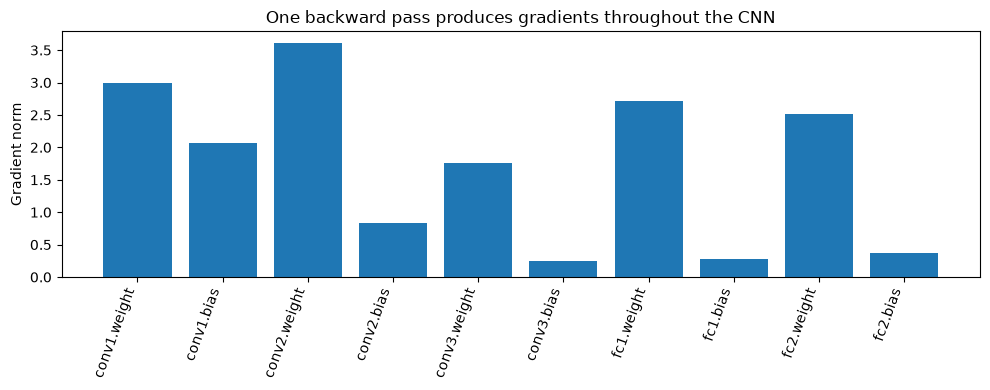

In [22]:
plt.figure(figsize=(10, 4))
plt.bar(
    gradient_table["parameter"],
    gradient_table["gradient norm"],
)
plt.xticks(rotation=70, ha="right")
plt.ylabel("Gradient norm")
plt.title("One backward pass produces gradients throughout the CNN")
plt.tight_layout()
plt.show()


## 11. Why `zero_grad()` matters: gradients accumulate

This behavior is deliberate because some advanced workflows intentionally accumulate gradients over several minibatches. For ordinary minibatch training, though, we clear them each time.


In [23]:
# Make another disposable model copy.
accum_model = copy.deepcopy(model).to(device)
accum_model.train()

loss_fn = nn.CrossEntropyLoss()

# Start with empty gradients.
accum_model.zero_grad(set_to_none=True)

# First forward/backward on the SAME minibatch.
loss1 = loss_fn(accum_model(X_small), y_small)
loss1.backward()
grad_after_one = accum_model.conv1.weight.grad.detach().clone()

# Do NOT zero gradients.
# Run the exact same forward/backward again.
loss2 = loss_fn(accum_model(X_small), y_small)
loss2.backward()
grad_after_two = accum_model.conv1.weight.grad.detach().clone()

ratio = (
    grad_after_two.norm() / grad_after_one.norm()
).item()

print("Gradient norm after one backward:", grad_after_one.norm().item())
print("Gradient norm after two:         ", grad_after_two.norm().item())
print("Ratio (same batch twice):        ", ratio)
print("Expected: approximately 2.0")


Gradient norm after one backward: 2.988985300064087
Gradient norm after two:          5.977970600128174
Ratio (same batch twice):         2.0
Expected: approximately 2.0


# Part IV — The training/evaluation code, heavily commented

Now the functions from Notebook 07 should look much less like ritual spellcasting.


## 12. `evaluate_model()`, line by line

Evaluation means:

- do **not** update weights,
- do **not** build gradient graphs,
- gather predictions and losses over the whole validation set.


In [24]:
def evaluate_model_commented(model, loader, loss_fn):
    # Switch layers into inference behavior.
    # Important for Dropout / BatchNorm in models that use them.
    model.eval()

    # Running totals are ordinary Python numbers.
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    # We will collect every true and predicted class so sklearn can analyze them later.
    all_true = []
    all_pred = []

    # Evaluation never calls backward(), so do not build autograd graphs.
    # This reduces memory use and unnecessary work.
    with torch.no_grad():

        # DataLoader yields one minibatch at a time.
        for X_batch, y_batch in loader:

            # DataLoader tensors begin on CPU.
            # Move them to the same device as the model.
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # FORWARD PASS ONLY.
            # Shape: [batch, 6, 100] → [batch, 3 logits].
            logits = model(X_batch)

            # Calculate this minibatch's average cross-entropy loss.
            loss = loss_fn(logits, y_batch)

            # Pick the class with the largest logit for each example.
            # dim=1 means search across the class dimension.
            predictions = logits.argmax(dim=1)

            # CrossEntropyLoss returns the MEAN loss in this minibatch.
            # Multiply by batch size so we can later calculate a proper dataset-wide mean,
            # even if the final minibatch is smaller than the others.
            total_loss += loss.item() * len(y_batch)

            # (predictions == y_batch) creates a Boolean tensor.
            # sum() counts True values.
            # item() converts the one-number tensor to a Python scalar.
            total_correct += (
                predictions == y_batch
            ).sum().item()

            total_examples += len(y_batch)

            # sklearn / NumPy live on the CPU.
            # These tensors do not require gradients because we are inside no_grad().
            # .cpu() moves values from CUDA/MPS to CPU RAM if necessary.
            # .numpy() exposes those CPU values as NumPy arrays.
            all_true.append(y_batch.cpu().numpy())
            all_pred.append(predictions.cpu().numpy())

    # concatenate joins the list of minibatch arrays into one long array.
    y_true = np.concatenate(all_true)
    y_pred = np.concatenate(all_pred)

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
        "y_true": y_true,
        "y_pred": y_pred,
    }


In [25]:
# Try the heavily commented evaluator on our held-out person.
val_loader = make_loader(X_val, y_val, batch_size=256, shuffle=False)
loss_fn = nn.CrossEntropyLoss()

result = evaluate_model_commented(model, val_loader, loss_fn)

print("Validation loss:    ", result["loss"])
print("Validation accuracy:", result["accuracy"])
print("Macro F1:           ", f1_score(result["y_true"], result["y_pred"], average="macro"))


Validation loss:     0.3021489977836609
Validation accuracy: 0.8961038961038961
Macro F1:            0.8565154673317593


## 13. One training epoch, line by line

The core pattern repeats once per minibatch:

```text
zero gradients
→ forward
→ loss
→ backward
→ optimizer step
```

An **epoch** is just one complete pass through all minibatches in the training dataset.


In [26]:
def train_one_epoch_commented(model, loader, loss_fn, optimizer):
    # Put model in training behavior.
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_examples = 0

    # One loop iteration = one minibatch = one optimizer update.
    for X_batch, y_batch in loader:

        # Move the current minibatch to the model's device.
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # PyTorch accumulates gradients, so clear gradients from the previous batch.
        # set_to_none=True is an efficient way to say "there is no gradient yet."
        optimizer.zero_grad(set_to_none=True)

        # FORWARD PASS.
        # PyTorch records the operations because parameters require gradients.
        logits = model(X_batch)

        # Turn the batch of predictions + correct labels into ONE scalar objective.
        loss = loss_fn(logits, y_batch)

        # BACKWARD PASS.
        # Populate parameter.grad throughout the network using the chain rule.
        loss.backward()

        # UPDATE PARAMETERS.
        # Adam reads each .grad and changes the corresponding parameter.
        optimizer.step()

        # Everything below is just bookkeeping for human-readable training metrics.
        train_loss_sum += loss.item() * len(y_batch)

        predictions = logits.argmax(dim=1)
        train_correct += (
            predictions == y_batch
        ).sum().item()

        train_examples += len(y_batch)

    return {
        "loss": train_loss_sum / train_examples,
        "accuracy": train_correct / train_examples,
    }


### Why we usually do not call `.detach()` inside the training calculations

During the forward pass we **want** the loss to remain connected to the model parameters through the computation graph. If we detached the logits before calculating the loss, backpropagation would have no path back to the weights.

So:

```text
training math            KEEP graph attached
plotting / NumPy export  DETACH from graph
```


# Part V — Carry one real window through the entire network

Now for the fun bit. We will manually reproduce `forward()` **one line at a time** and keep every intermediate result.

We will expose both **pre-activation scores** and **post-ReLU activations** where useful.


## 14. Pick one held-out Walking window

Using the held-out person means the example was not used for gradient descent.


In [27]:
walking_class = class_to_index["Walking"]
walking_candidates = np.where(y_val.numpy() == walking_class)[0]
trace_index = walking_candidates[len(walking_candidates) // 2]

# KEEP batch dimension: [1, 6, 100]
x = X_val[trace_index:trace_index + 1].to(device)
y_true_index = int(y_val[trace_index].item())
y_true_name = class_names[y_true_index]

print("True activity:", y_true_name)
print("Input shape:", tuple(x.shape))


True activity: Walking
Input shape: (1, 6, 100)


## 15. The entire forward pass, manually exposed

This is effectively `model.forward(x)`, but with the hood removed.


In [28]:
model.eval()

with torch.no_grad():

    # ------------------------------------------------------------
    # INPUT
    # ------------------------------------------------------------
    raw = x

    # Standardize each of the six sensor channels using TRAINING-set statistics.
    standardized = model.standardize(raw)

    # ------------------------------------------------------------
    # CONVOLUTION BLOCK 1
    # ------------------------------------------------------------
    # Each of 32 filters slides across all 6 input channels.
    conv1_pre = model.conv1(standardized)

    # ReLU replaces negative convolution scores with zero.
    conv1_relu = F.relu(conv1_pre)

    # Keep the maximum from each neighboring pair of time positions.
    pool1 = model.pool1(conv1_relu)

    # ------------------------------------------------------------
    # CONVOLUTION BLOCK 2
    # ------------------------------------------------------------
    # The 64 Conv2 filters now slide across the 32 Pool1 feature channels.
    conv2_pre = model.conv2(pool1)
    conv2_relu = F.relu(conv2_pre)
    pool2 = model.pool2(conv2_relu)

    # ------------------------------------------------------------
    # CONVOLUTION BLOCK 3
    # ------------------------------------------------------------
    conv3_pre = model.conv3(pool2)
    conv3_relu = F.relu(conv3_pre)

    # ------------------------------------------------------------
    # GLOBAL AVERAGE POOLING
    # ------------------------------------------------------------
    # Average every one of the 64 feature maps across its 25 time positions.
    # Shape [1, 64, 25] → [1, 64, 1].
    gap_3d = model.gap(conv3_relu)

    # Remove the final length-1 dimension: [1, 64, 1] → [1, 64].
    gap = gap_3d.squeeze(-1)

    # ------------------------------------------------------------
    # FULLY CONNECTED HIDDEN LAYER
    # ------------------------------------------------------------
    # 64 learned pooled features → 32 weighted combinations.
    fc1_pre = model.fc1(gap)

    # Again, ReLU clips negative hidden-unit scores to zero.
    fc1_relu = F.relu(fc1_pre)

    # ------------------------------------------------------------
    # FINAL CLASSIFICATION LAYER
    # ------------------------------------------------------------
    # 32 hidden features → one raw score for each activity class.
    logits = model.fc2(fc1_relu)

    # Softmax is NOT needed for CrossEntropyLoss during training.
    # Here, after training, it is useful because it converts logits to probabilities.
    probabilities = torch.softmax(logits, dim=1)

    # Highest logit = highest softmax probability = predicted class.
    predicted_index = int(logits.argmax(dim=1).item())
    predicted_name = class_names[predicted_index]

print("True class:     ", y_true_name)
print("Predicted class:", predicted_name)


True class:      Walking
Predicted class: Walking


In [29]:
# A shape/value-count audit makes the dimensional story very concrete.
stages = {
    "raw input": raw,
    "standardized": standardized,
    "conv1 pre-ReLU": conv1_pre,
    "conv1 ReLU": conv1_relu,
    "pool1": pool1,
    "conv2 pre-ReLU": conv2_pre,
    "conv2 ReLU": conv2_relu,
    "pool2": pool2,
    "conv3 pre-ReLU": conv3_pre,
    "conv3 ReLU": conv3_relu,
    "GAP before squeeze": gap_3d,
    "GAP 64-vector": gap,
    "FC1 pre-ReLU": fc1_pre,
    "FC1 ReLU": fc1_relu,
    "logits": logits,
    "softmax probabilities": probabilities,
}

rows = []

for name, tensor in stages.items():
    t = tensor.detach()
    rows.append({
        "stage": name,
        "shape": str(tuple(t.shape)),
        "number of values": t.numel(),
        "minimum": t.min().item(),
        "maximum": t.max().item(),
        "mean": t.float().mean().item(),
    })

stage_table = pd.DataFrame(rows)
display(stage_table)


,stage,shape,number of values,minimum,maximum,mean
0,raw input,"(1, 6, 100)",600,-7.469337,4.452796,-0.034111
1,standardized,"(1, 6, 100)",600,-2.391457,1.544199,-0.010480
2,conv1 pre-ReLU,"(1, 32, 100)",3200,-1.888542,1.920282,0.038343
3,conv1 ReLU,"(1, 32, 100)",3200,0.000000,1.920282,0.207720
4,pool1,"(1, 32, 50)",1600,0.000000,1.920282,0.253412
5,conv2 pre-ReLU,"(1, 64, 50)",3200,-1.915356,1.739551,0.213059
6,conv2 ReLU,"(1, 64, 50)",3200,0.000000,1.739551,0.317644
7,pool2,"(1, 64, 25)",1600,0.000000,1.739551,0.385630
8,conv3 pre-ReLU,"(1, 64, 25)",1600,-3.204891,6.934563,0.432682
9,conv3 ReLU,"(1, 64, 25)",1600,0.000000,6.934563,0.854651


## 16. Plot every stage of that one Walking window

The exact meaning changes as we descend the network:

```text
sensor values
→ local pattern scores
→ positive feature detections
→ pooled detections
→ deeper learned motifs
→ 64 global learned features
→ 32 fully connected hidden features
→ 3 logits
→ 3 probabilities
```


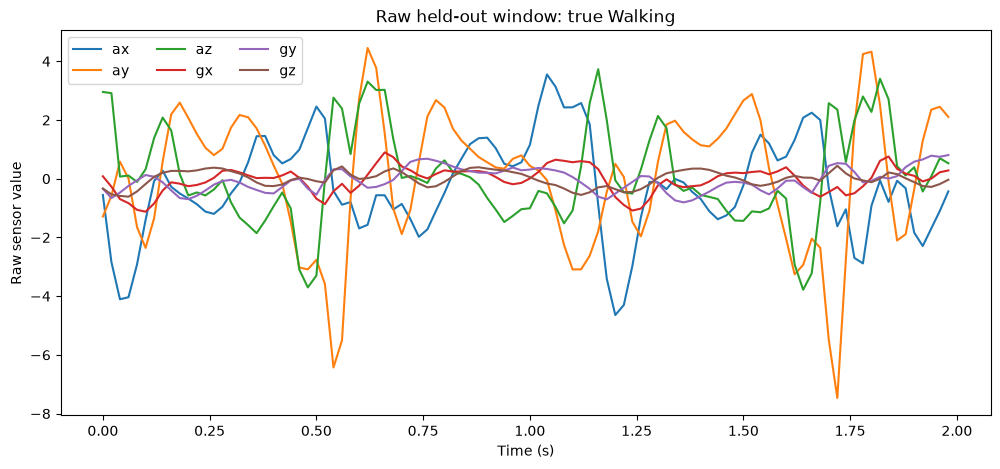

In [30]:
# RAW INPUT: six sensor channels through time.
raw_np = raw[0].detach().cpu().numpy()

t = np.arange(raw_np.shape[1]) / FS

plt.figure(figsize=(12, 5))
for channel_index, channel_name in enumerate(CHANNELS):
    plt.plot(t, raw_np[channel_index], label=channel_name)
plt.xlabel("Time (s)")
plt.ylabel("Raw sensor value")
plt.title(f"Raw held-out window: true {y_true_name}")
plt.legend(ncol=3)
plt.show()


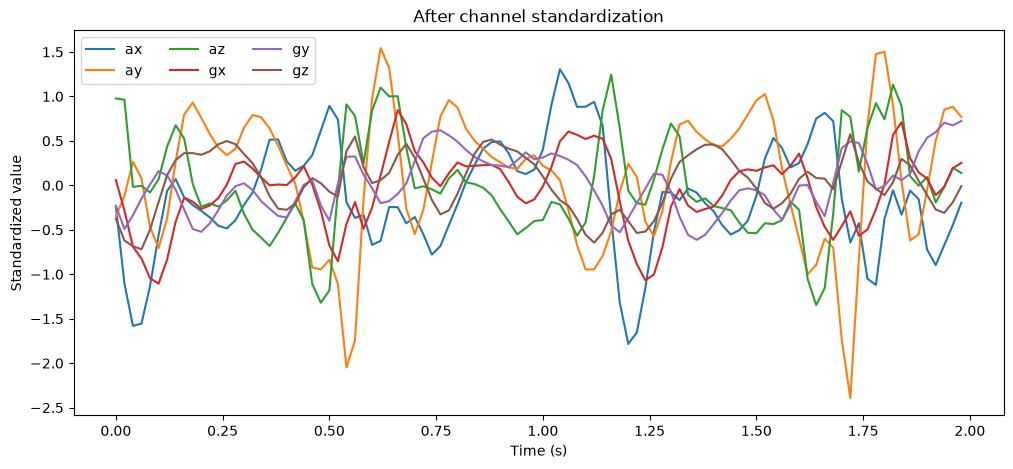

In [31]:
# STANDARDIZED INPUT: same six waveforms, now in training-set standard-deviation units.
std_np = standardized[0].detach().cpu().numpy()

plt.figure(figsize=(12, 5))
for channel_index, channel_name in enumerate(CHANNELS):
    plt.plot(t, std_np[channel_index], label=channel_name)
plt.xlabel("Time (s)")
plt.ylabel("Standardized value")
plt.title("After channel standardization")
plt.legend(ncol=3)
plt.show()


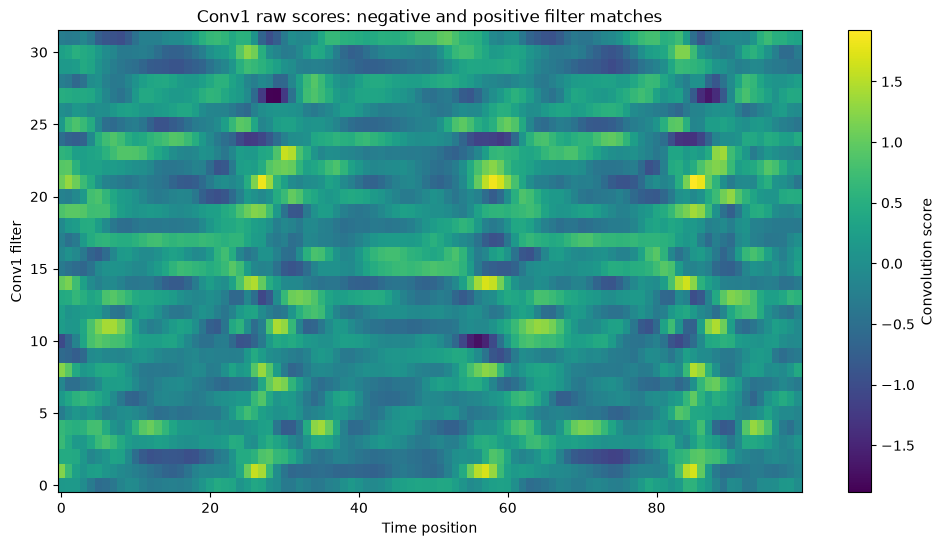

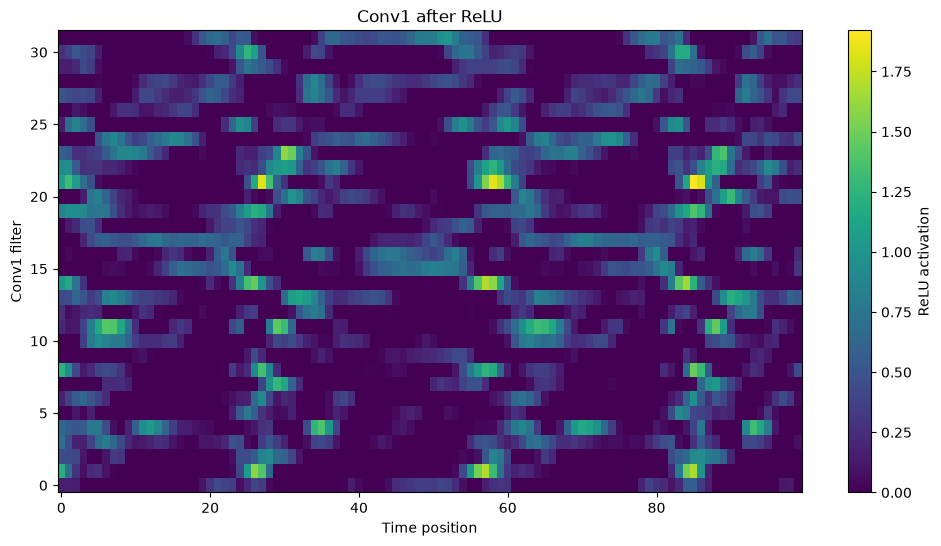

In [32]:
# CONV1 BEFORE ReLU: signed detector scores.
plt.figure(figsize=(12, 6))
plt.imshow(conv1_pre[0].detach().cpu().numpy(), aspect="auto", origin="lower")
plt.xlabel("Time position")
plt.ylabel("Conv1 filter")
plt.title("Conv1 raw scores: negative and positive filter matches")
plt.colorbar(label="Convolution score")
plt.show()

# CONV1 AFTER ReLU: negative scores become zero.
plt.figure(figsize=(12, 6))
plt.imshow(conv1_relu[0].detach().cpu().numpy(), aspect="auto", origin="lower")
plt.xlabel("Time position")
plt.ylabel("Conv1 filter")
plt.title("Conv1 after ReLU")
plt.colorbar(label="ReLU activation")
plt.show()


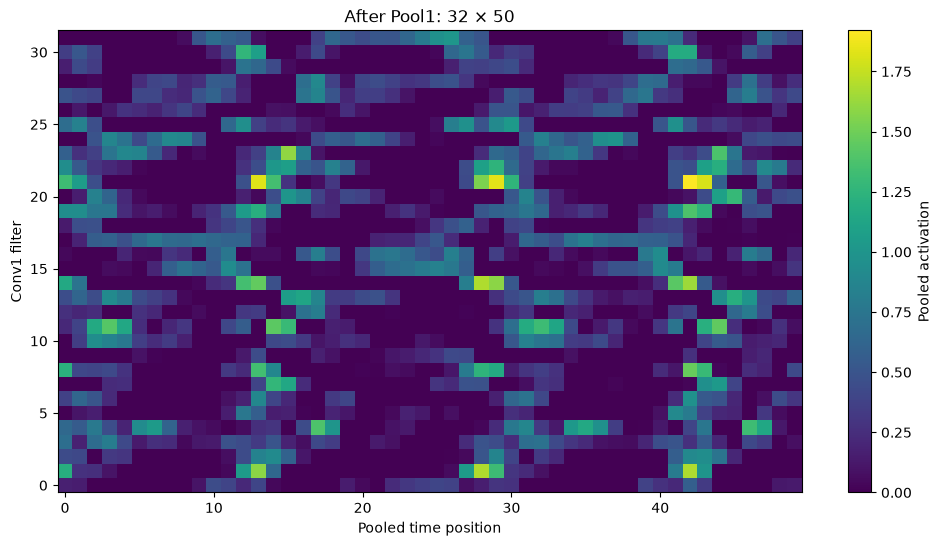

In [33]:
# POOL1: same 32 filters, half the time resolution.
plt.figure(figsize=(12, 6))
plt.imshow(pool1[0].detach().cpu().numpy(), aspect="auto", origin="lower")
plt.xlabel("Pooled time position")
plt.ylabel("Conv1 filter")
plt.title("After Pool1: 32 × 50")
plt.colorbar(label="Pooled activation")
plt.show()


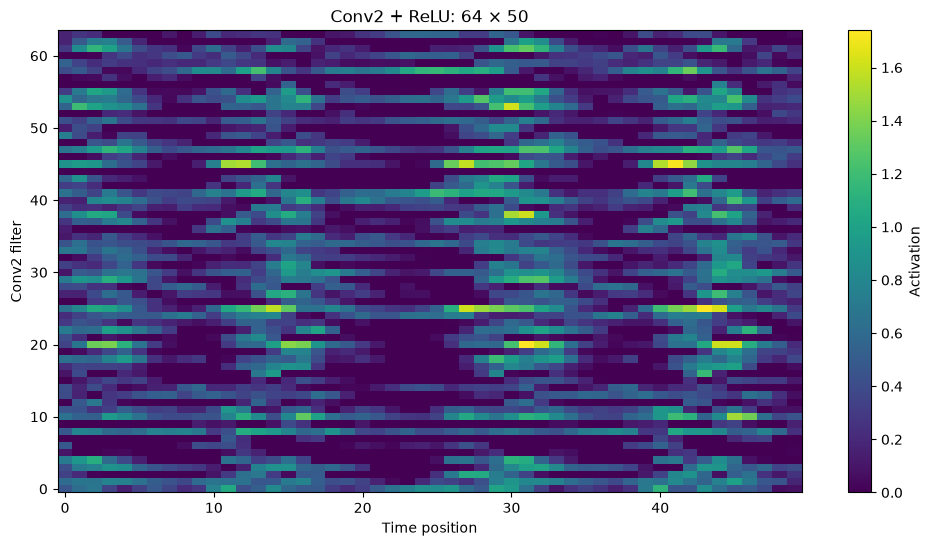

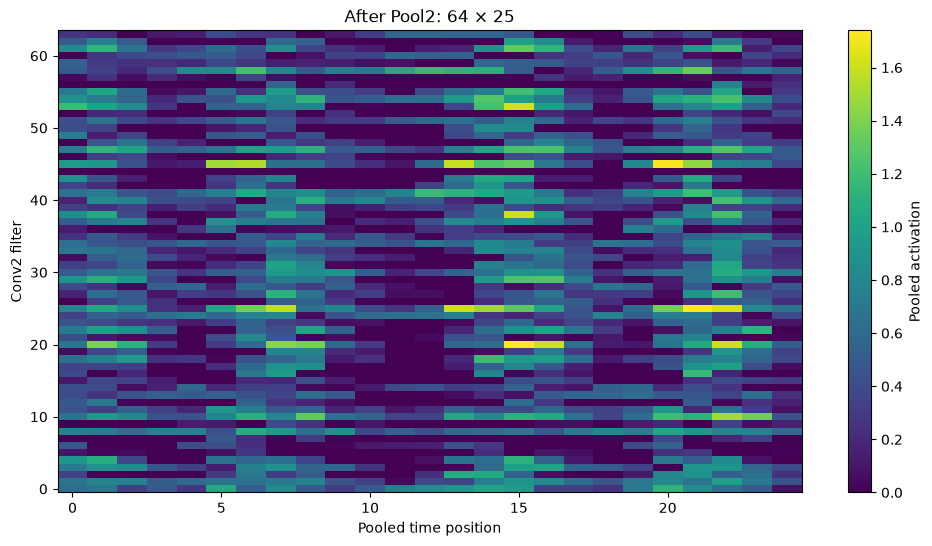

In [34]:
# CONV2 after ReLU.
plt.figure(figsize=(12, 6))
plt.imshow(conv2_relu[0].detach().cpu().numpy(), aspect="auto", origin="lower")
plt.xlabel("Time position")
plt.ylabel("Conv2 filter")
plt.title("Conv2 + ReLU: 64 × 50")
plt.colorbar(label="Activation")
plt.show()

# POOL2.
plt.figure(figsize=(12, 6))
plt.imshow(pool2[0].detach().cpu().numpy(), aspect="auto", origin="lower")
plt.xlabel("Pooled time position")
plt.ylabel("Conv2 filter")
plt.title("After Pool2: 64 × 25")
plt.colorbar(label="Pooled activation")
plt.show()


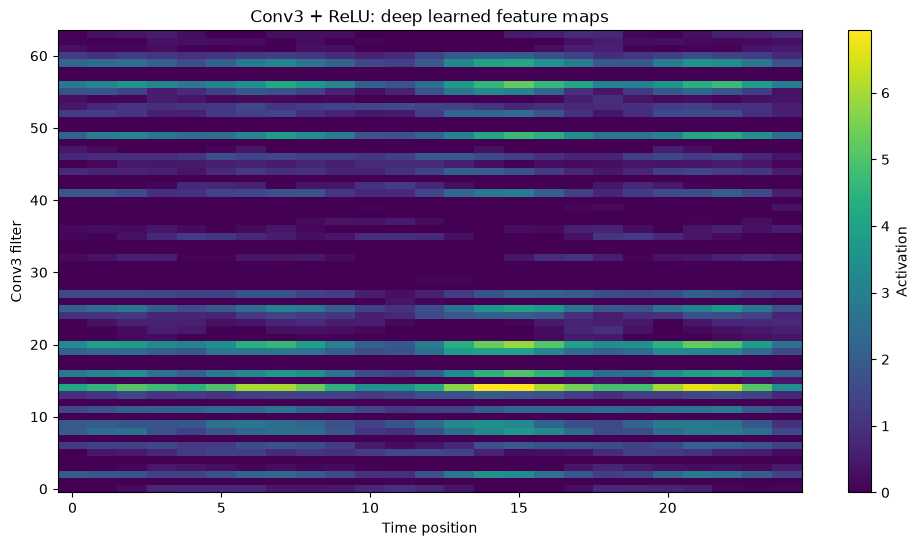

In [35]:
# CONV3 after ReLU: 64 deep feature maps, each with a receptive field of ~40 original samples.
plt.figure(figsize=(12, 6))
plt.imshow(conv3_relu[0].detach().cpu().numpy(), aspect="auto", origin="lower")
plt.xlabel("Time position")
plt.ylabel("Conv3 filter")
plt.title("Conv3 + ReLU: deep learned feature maps")
plt.colorbar(label="Activation")
plt.show()


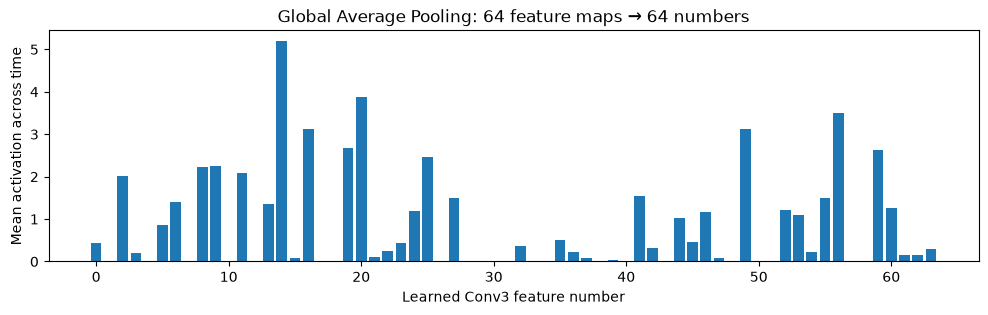

In [36]:
# GLOBAL AVERAGE POOLING: one number per Conv3 filter.
gap_np = gap[0].detach().cpu().numpy()

plt.figure(figsize=(12, 3))
plt.bar(np.arange(len(gap_np)), gap_np)
plt.xlabel("Learned Conv3 feature number")
plt.ylabel("Mean activation across time")
plt.title("Global Average Pooling: 64 feature maps → 64 numbers")
plt.show()


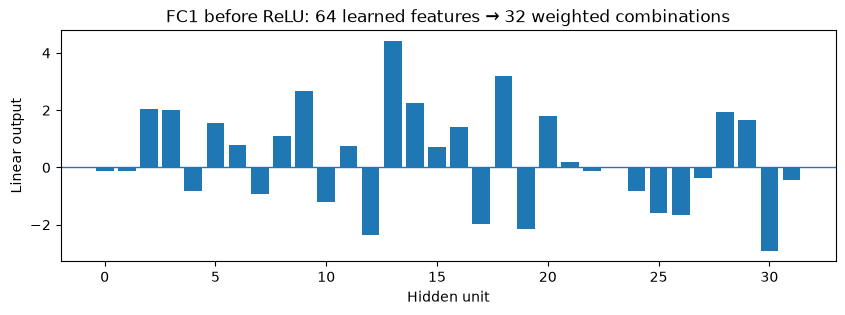

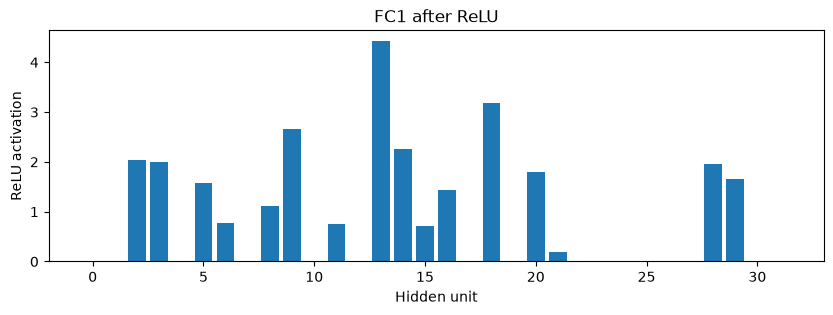

In [37]:
# FULLY CONNECTED HIDDEN LAYER: signed linear scores before ReLU.
fc1_pre_np = fc1_pre[0].detach().cpu().numpy()
fc1_relu_np = fc1_relu[0].detach().cpu().numpy()

plt.figure(figsize=(10, 3))
plt.bar(np.arange(len(fc1_pre_np)), fc1_pre_np)
plt.axhline(0, linewidth=1)
plt.xlabel("Hidden unit")
plt.ylabel("Linear output")
plt.title("FC1 before ReLU: 64 learned features → 32 weighted combinations")
plt.show()

plt.figure(figsize=(10, 3))
plt.bar(np.arange(len(fc1_relu_np)), fc1_relu_np)
plt.xlabel("Hidden unit")
plt.ylabel("ReLU activation")
plt.title("FC1 after ReLU")
plt.show()


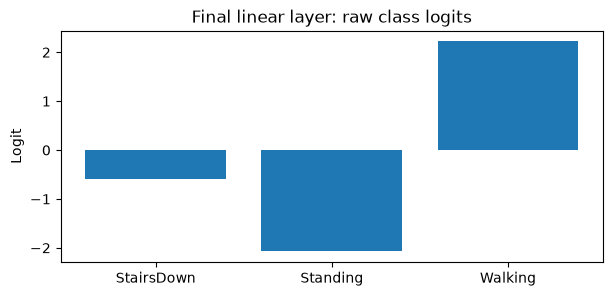

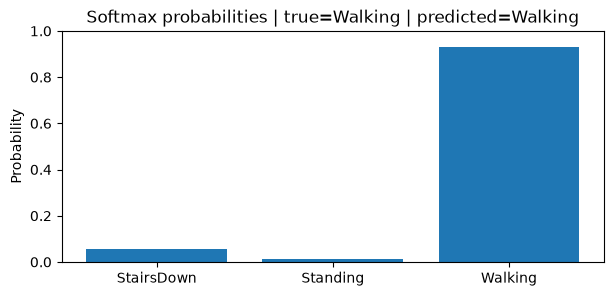

Logits:
  StairsDown   -0.5847
  Standing     -2.0735
  Walking       2.2210

Probabilities:
  StairsDown    0.0563
  Standing      0.0127
  Walking       0.9310

Probability sum: 1.0


In [38]:
# FINAL LOGITS: raw class evidence.
logits_np = logits[0].detach().cpu().numpy()
probs_np = probabilities[0].detach().cpu().numpy()

plt.figure(figsize=(7, 3))
plt.bar(class_names, logits_np)
plt.ylabel("Logit")
plt.title("Final linear layer: raw class logits")
plt.show()

# SOFTMAX: same ranking, converted to probabilities summing to 1.
plt.figure(figsize=(7, 3))
plt.bar(class_names, probs_np)
plt.ylim(0, 1)
plt.ylabel("Probability")
plt.title(
    f"Softmax probabilities | true={y_true_name} | predicted={predicted_name}"
)
plt.show()

print("Logits:")
for name, value in zip(class_names, logits_np):
    print(f"  {name:12s} {value: .4f}")

print("\nProbabilities:")
for name, value in zip(class_names, probs_np):
    print(f"  {name:12s} {value: .4f}")

print("\nProbability sum:", probs_np.sum())


## 17. Do it for one window of **each activity**

Rather than rewriting the whole forward pass three times, package the same exposed operations into a tracing helper.

The helper is not doing anything new. It simply saves all the intermediate tensors in a dictionary.


In [39]:
def trace_window(model, x_one):
    # Run one [1, 6, 100] window through every stage and return all intermediates.
    model.eval()

    with torch.no_grad():
        raw = x_one.to(device)
        standardized = model.standardize(raw)

        conv1_pre = model.conv1(standardized)
        conv1_relu = F.relu(conv1_pre)
        pool1 = model.pool1(conv1_relu)

        conv2_pre = model.conv2(pool1)
        conv2_relu = F.relu(conv2_pre)
        pool2 = model.pool2(conv2_relu)

        conv3_pre = model.conv3(pool2)
        conv3_relu = F.relu(conv3_pre)

        gap = model.gap(conv3_relu).squeeze(-1)

        fc1_pre = model.fc1(gap)
        fc1_relu = F.relu(fc1_pre)

        logits = model.fc2(fc1_relu)
        probabilities = torch.softmax(logits, dim=1)

    return {
        "raw": raw,
        "standardized": standardized,
        "conv1_relu": conv1_relu,
        "pool1": pool1,
        "conv2_relu": conv2_relu,
        "pool2": pool2,
        "conv3_relu": conv3_relu,
        "gap": gap,
        "fc1_pre": fc1_pre,
        "fc1_relu": fc1_relu,
        "logits": logits,
        "probabilities": probabilities,
    }


In [40]:
# Pick a middle held-out example from each activity.
representative_rows = []
representatives = {}

for class_index, class_name in enumerate(class_names):
    candidates = np.where(y_val.numpy() == class_index)[0]
    idx = candidates[len(candidates) // 2]

    trace = trace_window(
        model,
        X_val[idx:idx + 1],
    )

    probabilities_np = trace["probabilities"][0].cpu().numpy()
    predicted_index = int(trace["logits"].argmax(dim=1).item())

    representatives[class_name] = {
        "index": idx,
        "trace": trace,
    }

    representative_rows.append({
        "true activity": class_name,
        "predicted activity": class_names[predicted_index],
        **{
            f"P({name})": probabilities_np[j]
            for j, name in enumerate(class_names)
        },
    })

representative_table = pd.DataFrame(representative_rows)
display(representative_table)


,true activity,predicted activity,P(StairsDown),P(Standing),P(Walking)
0,StairsDown,StairsDown,0.976548,0.012333,0.011119
1,Standing,Standing,0.021854,0.962770,0.015376
2,Walking,Walking,0.056294,0.012702,0.931003


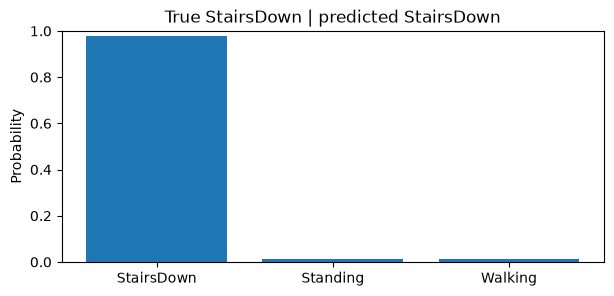

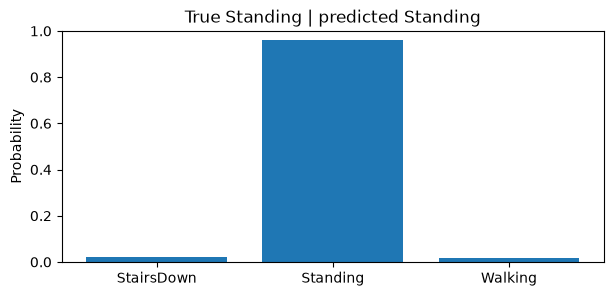

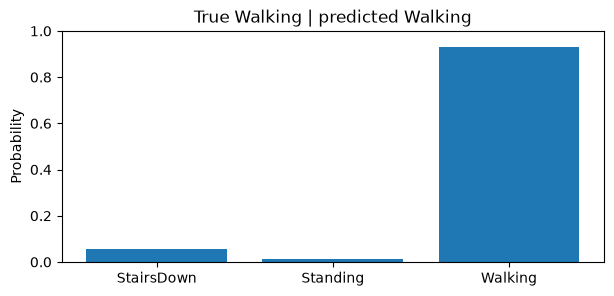

In [41]:
# Plot the final probability vector for one representative of each activity.
for class_name, bundle in representatives.items():
    trace = bundle["trace"]
    probs = trace["probabilities"][0].cpu().numpy()
    predicted = class_names[int(trace["logits"].argmax(dim=1).item())]

    plt.figure(figsize=(7, 3))
    plt.bar(class_names, probs)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"True {class_name} | predicted {predicted}")
    plt.show()


### Optional: full internal heatmap trace for all three activities

This can make a lot of figures, so it is separated from the main path. It is very cool for discussion because the **same trained filters** produce very different activation patterns for different activities.


In [ ]:
PLOT_FULL_TRACE_FOR_ALL_CLASSES = True

if PLOT_FULL_TRACE_FOR_ALL_CLASSES:

    for class_name, bundle in representatives.items():
        trace = bundle["trace"]

        print("=" * 70)
        print(class_name)
        print("=" * 70)

        for stage_name in [
            "conv1_relu",
            "pool1",
            "conv2_relu",
            "pool2",
            "conv3_relu",
        ]:
            array = trace[stage_name][0].cpu().numpy()

            plt.figure(figsize=(11, 5))
            plt.imshow(array, aspect="auto", origin="lower")
            plt.xlabel("Time position")
            plt.ylabel("Feature channel")
            plt.title(f"{class_name}: {stage_name} | shape {array.shape}")
            plt.colorbar(label="Activation")
            plt.show()


# Final conceptual map

By this point the PyTorch model can be read almost literally:

```text
DATA
X_batch.to(device)
        ↓
FORWARD PASS
local learned detectors
        ↓
ReLU
keep positive evidence
        ↓
MaxPool
keep strong local evidence, reduce timing precision
        ↓
more convolution / pooling
larger receptive fields + deeper motifs
        ↓
Global Average Pool
64 time-independent-ish learned summary features
        ↓
Linear + ReLU
32 learned combinations
        ↓
Linear
3 logits
        ↓
softmax (only when we want probabilities)
        ↓
prediction

TRAINING ADDS:
loss
  ↓
backward()
  ↓
gradients in every trainable parameter
  ↓
optimizer.step()
  ↓
slightly changed detector and classifier weights
```


## Breakout checkpoint

Be ready to explain without code:

1. What exactly does one `MaxPool1d(2)` output equal?
2. Why does pooling halve time resolution but leave the number of filters unchanged?
3. What information does pooling discard?
4. What is the difference between a **parameter**, a **gradient**, and a **buffer**?
5. Why are the input sensor tensors usually `requires_grad=False` while model parameters are `True`?
6. What does `.to(device)` do?
7. Why is `.detach().cpu().numpy()` such a common sequence for inspection and plotting?
8. What is the difference between `model.eval()` and `torch.no_grad()`?
9. What does `loss.backward()` calculate?
10. Why does `backward()` itself not change the weights?
11. What does `optimizer.step()` do?
12. Why must ordinary minibatch training clear gradients before the next batch?
13. What is the difference between logits and softmax probabilities?
14. What happened to the representation's shape from `6 × 100` input to the final 3 logits?
15. Why can the fully connected layer be thought of as combining the 64 learned CNN features into evidence for the activity classes?

Then return to Notebook 07 and continue the feature-map / learned-detector story.
